# DeepNT+ IPv6 Experiments

Trains and evaluates DeepNT+ and all baseline models on the 5 reconstructed **IPv6 CAIDA Ark** topology graphs (scq-es, prg-cz, cdg4-fr, san-us, iad-us).

**Protocol**: Graph-level split (graph_01..03 train, graph_04 val, graph_05 test). Total 7,500 paths (1,500 paths per graph), 12,649 nodes, 14,715 edges across 5 global Ark monitors.


In [1]:
import sys
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    THESIS = Path("/content/drive/My Drive/Thesis")
else:
    THESIS = Path(r"C:\Users\KINGDOM\Desktop\Thesis")
PROJECT_ROOT = THESIS / "DeepNT_Output"
PROCESSED = PROJECT_ROOT / "reconstructed_dataset" / "ipv6"
# the deepnt_plus package folder: in Colab copy it to  DeepNT_Output/code/deepnt_plus
candidates = [PROJECT_ROOT / "code", THESIS / "colab", Path.cwd(), Path.cwd().parent]
pkg_root = next((c for c in candidates if (c / "deepnt_plus" / "__init__.py").exists()), None)
if pkg_root is None:
    raise FileNotFoundError("deepnt_plus package not found. Copy the folder 'deepnt_plus' to "
                            f"{PROJECT_ROOT / 'code'} (searched: {[str(c) for c in candidates]})")
sys.path.insert(0, str(pkg_root))
REQUIRED_FILES = ["paths_all.csv", "path_ground_truth.csv", "node_features.csv", "edge_features.csv",
                  "tomography/A_graph_01.npz"]
def find_missing():
    return [f for f in REQUIRED_FILES if not (PROCESSED / f).exists()]
missing = find_missing()
if missing and IN_COLAB:
    # files added to Drive from outside this session (browser upload) are invisible to a stale mount
    print("files not visible, refreshing the Drive mount ...")
    drive.mount('/content/drive', force_remount=True)
    missing = find_missing()
if missing:
    seen = sorted(p.name for p in PROCESSED.parent.iterdir()) if PROCESSED.parent.exists() else "(folder does not exist)"
    seen_proc = sorted(p.name for p in PROCESSED.iterdir()) if PROCESSED.exists() else "(folder does not exist)"
    raise FileNotFoundError(f"missing in {PROCESSED}: {missing}\n"
                            f"this session sees data/: {seen}\nthis session sees data/processed/: {seen_proc}\n"
                            "If the files are in Drive but not listed here: Runtime > Disconnect and delete runtime, rerun, "
                            "and check the browser and Colab use the same Google account. Otherwise run Dataset_Build.ipynb.")
print("package:", pkg_root / "deepnt_plus", "\ndata   :", PROCESSED)


package: C:\Users\KINGDOM\Desktop\Thesis\colab\deepnt_plus 
data   : C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\reconstructed_dataset\ipv6


In [2]:
import pandas as pd
import torch
from deepnt_plus import active, report
from deepnt_plus.data import describe, load_dataset
from deepnt_plus.run import ABLATIONS, VARIANTS, run_all, summarise
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
SEEDS = (0, 1, 2, 3, 4)          # small data: report mean +- std over seeds
EPOCHS = 40  # 40 epochs optimal with CosineAnnealingLR + patience 15
RUN_ABLATIONS = True
RUN_ACTIVE_LEARNING = True
FAST = False               # True = smaller model, for a quick smoke test
RUN_NAME = "run_ipv6_balanced"      # run_01 = initial run, run_02 = 15-graph run, run_03 = updated 5 compressed graphs
OUT_DIR = PROJECT_ROOT / "experiments" / "deepnt" / RUN_NAME
graphs, norm = load_dataset(PROCESSED)
overview = describe(graphs)
print(overview.to_string(index=False))
n_tr = overview[overview.split == "train"]
print(f"\ntrain graphs: {int(n_tr.paths.sum())} paths ({int(n_tr.observed.sum())} observed) | "
      f"val hidden paths: {int(overview[overview.split == 'val'].hidden.sum())} | "
      f"test hidden paths: {int(overview[overview.split == 'test'].hidden.sum())}")
print(f"PyTorch {torch.__version__} | packet-loss labels present: "
      f"{bool(any((~torch.isnan(g.loss)).any() for g in graphs.values()))}")


   graph split  nodes  edges  paths  observed  hidden  outliers  median_rtt_ms
graph_01 train   2444   2702   1500       675     825         0     520.383972
graph_02 train   2621   3014   1500       675     825         0     501.898987
graph_03   val   3039   3622   1500       675     825         0     475.632996
graph_04 train   1765   2018   1500       675     825         0     525.976990
graph_05  test   2780   3359   1500       675     825         0     506.226013

train graphs: 4500 paths (2025 observed) | val hidden paths: 825 | test hidden paths: 825
PyTorch 2.14.0+cpu | packet-loss labels present: False


In [3]:
gt = pd.read_csv(PROCESSED / "path_ground_truth.csv")
flagged = gt[gt["quality_flag"].astype(str).str.contains("rtt_outlier")]
print(f"{len(flagged)} of {len(gt)} paths are flagged as RTT outliers and left out of context, training and metrics "
      f"(rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:")
print(flagged[["path_id", "graph_id", "split", "rtt_ms", "quality_flag"]].round(1).to_string(index=False) if len(flagged) else "none")
print("\nmonitors per split:")
paths_all = pd.read_csv(PROCESSED / "paths_all.csv")
print(paths_all.groupby(["split", "monitor_id"]).size().unstack(fill_value=0).to_string())


0 of 7500 paths are flagged as RTT outliers and left out of context, training and metrics (rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:
none

monitors per split:
monitor_id  cdg4-fr  iad-us  prg-cz  san-us  scq-es
split                                              
test              0    1500       0       0       0
train             0       0    1500    1500    1500
val            1500       0       0       0       0


## Train and evaluate everything

Baselines (median, hop-count, LR, RF, MLP, classical convex tomography), GraphSAGE, GAT, DeepNT (static), DeepNT+ (full) and the
ablations, over several seeds. Writes `predictions.csv`, `metrics_summary.csv`, `history.csv`, `config.json` and the checkpoints
to `experiments/deepnt/<run>/`.

In [4]:
pred, summary = run_all(PROCESSED, OUT_DIR, seeds=SEEDS, epochs=EPOCHS, ablations=RUN_ABLATIONS,
                        active_learning=RUN_ACTIVE_LEARNING, fast=FAST)
print("saved to", OUT_DIR)


5 graphs | packet-loss labels available: False
--- GraphSAGE | seed 0
epoch   1 | train loss 0.7299 | val MAE 250.10 ms
epoch  10 | train loss 0.7007 | val MAE 247.53 ms
epoch  20 | train loss 0.6830 | val MAE 248.23 ms
--- GraphSAGE | seed 1
epoch   1 | train loss 0.7211 | val MAE 250.07 ms
epoch  10 | train loss 0.6986 | val MAE 247.19 ms
epoch  20 | train loss 0.6795 | val MAE 248.02 ms
--- GraphSAGE | seed 2
epoch   1 | train loss 0.7253 | val MAE 250.16 ms
epoch  10 | train loss 0.6925 | val MAE 246.40 ms
epoch  20 | train loss 0.6998 | val MAE 249.32 ms
epoch  30 | train loss 0.6680 | val MAE 248.58 ms
--- GraphSAGE | seed 3
epoch   1 | train loss 0.7289 | val MAE 249.90 ms
epoch  10 | train loss 0.6989 | val MAE 247.04 ms
epoch  20 | train loss 0.6976 | val MAE 248.15 ms
--- GraphSAGE | seed 4
epoch   1 | train loss 0.7173 | val MAE 250.27 ms
epoch  10 | train loss 0.6903 | val MAE 249.22 ms
epoch  20 | train loss 0.6743 | val MAE 249.43 ms
--- GAT | seed 0
epoch   1 | train los

## Results on the hidden paths

Test graphs are scored once; validation graphs chose each checkpoint. `MAE`, `RMSE`, `MedAE` are in ms.

In [5]:
cols = ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean", "RMSE_mean", "R2_mean", "n_mean"]
cols = [c for c in cols if c in summary.columns]
for split in ("test", "val"):
    print(f"=== {split} graphs ===")
    print(summary[summary.split == split][cols].sort_values("MAE_mean").round(3).to_string(index=False))


=== test graphs ===
                           model  MAE_mean  MAE_std  MedAE_mean  MdAPE_mean  MAE_log_mean  RMSE_mean  R2_mean  n_mean
                          Median   242.672      NaN     237.537      38.580         0.687    284.415   -0.006   825.0
                Hop-count linear   242.674      NaN     236.650      38.875         0.687    284.125   -0.004   825.0
      DeepNT+ - tomography layer   243.371    0.336     237.107      40.765         0.688    283.687   -0.001   825.0
                             GAT   243.540    0.260     237.461      41.176         0.688    283.719   -0.001   825.0
                       GraphSAGE   243.724    0.443     237.191      41.491         0.689    283.877   -0.002   825.0
                 DeepNT (static)   246.083    0.358     241.419      39.655         0.693    289.230   -0.040   825.0
         DeepNT+ - convex fusion   248.999    3.936     241.365      39.308         0.698    294.347   -0.078   825.0
DeepNT+ - uncertainty (MSE only)   2

## Does each component earn its place?

Ablations remove one part of DeepNT+ (full). `delta_MAE` is the change against the full model, so a positive value means the part helps.
Read it next to `MAE_std`: with this little data, differences smaller than the seed-to-seed spread are not evidence.

In [6]:
test = summary[summary.split == "test"].set_index("model")
full = "DeepNT+ (full)"
if full in test.index:
    names = [n for n in list(ABLATIONS) + ["DeepNT (static, causal)", "DeepNT (static)", "GraphSAGE", "GAT"] if n in test.index]
    table = test.loc[names, ["MAE_mean", "MAE_std"]].copy()
    table["delta_MAE_vs_full"] = table["MAE_mean"] - test.loc[full, "MAE_mean"]
    table["larger_than_seed_spread"] = table["delta_MAE_vs_full"].abs() > (table["MAE_std"].fillna(0) + test.loc[full, "MAE_std"])
    print(f"{full}: MAE {test.loc[full, 'MAE_mean']:.3f} +- {test.loc[full, 'MAE_std']:.3f} ms\n")
    print(table.round(3).to_string())


DeepNT+ (full): MAE 254.730 +- 0.457 ms

                                  MAE_mean  MAE_std  delta_MAE_vs_full  larger_than_seed_spread
model                                                                                          
DeepNT+ - temporal branch          252.908    3.947             -1.822                    False
DeepNT+ - convex fusion            248.999    3.936             -5.731                     True
DeepNT+ - tomography layer         243.371    0.336            -11.359                     True
DeepNT+ - uncertainty (MSE only)   252.485    1.064             -2.245                     True
DeepNT+ - context features         253.690    1.157             -1.040                    False
DeepNT (static, causal)            252.994    3.837             -1.736                    False
DeepNT (static)                    246.083    0.358             -8.647                     True
GraphSAGE                          243.724    0.443            -11.005                     True

## Uncertainty calibration

`coverage_90` is the share of hidden paths whose true RTT falls inside the 90% predictive interval (ideal 0.90). `ECE_reg` is the mean
gap between nominal and empirical coverage over 50/80/90/95% (0 is perfect). `NLL` is in log-RTT space.

In [7]:
cal_cols = [c for c in ["model", "NLL_mean", "sharpness_log_mean", "coverage_50_mean", "coverage_80_mean",
                        "coverage_90_mean", "coverage_95_mean", "ECE_reg_mean"] if c in summary.columns]
print(summary[(summary.split == "test") & summary["ECE_reg_mean"].notna()][cal_cols].sort_values("ECE_reg_mean").round(3).to_string(index=False))


                           model   NLL_mean  sharpness_log_mean  coverage_50_mean  coverage_80_mean  coverage_90_mean  coverage_95_mean  ECE_reg_mean
      DeepNT+ - tomography layer      1.492               0.836             0.594             0.818             0.862             0.904         0.049
       DeepNT+ - temporal branch      1.544               0.832             0.598             0.802             0.848             0.895         0.052
         DeepNT (static, causal)      1.544               0.834             0.601             0.802             0.848             0.895         0.053
      DeepNT+ - context features      1.558               0.824             0.589             0.802             0.850             0.890         0.053
                 DeepNT (static)      1.519               0.830             0.608             0.808             0.857             0.895         0.053
         DeepNT+ - convex fusion      1.539               0.817             0.598             0.807 

## Active measurement scheduling (simulated)

On each test graph a quarter of the hidden paths is held out for scoring. Every round the strategy picks paths from the rest, their
real stored RTT is revealed to the model, and MAE is re-measured on the held-out paths. Lower curves mean better use of the probe budget.

In [8]:
ac_file = OUT_DIR / "active_learning.csv"
if ac_file.exists():
    curves = pd.read_csv(ac_file)
    mean_curve, auc = active.summarise(curves)
    print(auc.round(3).to_string(index=False))
    print("\n(mean MAE over rounds; 'random' is the reference every scheduler must beat)")
else:
    print("active learning was not run")


     strategy  mean_MAE_over_rounds
     variance               245.697
         bald               245.805
edge_coverage               245.836
       random               246.098
 longest_path               247.051

(mean MAE over rounds; 'random' is the reference every scheduler must beat)


## Figures

loss_curve.png


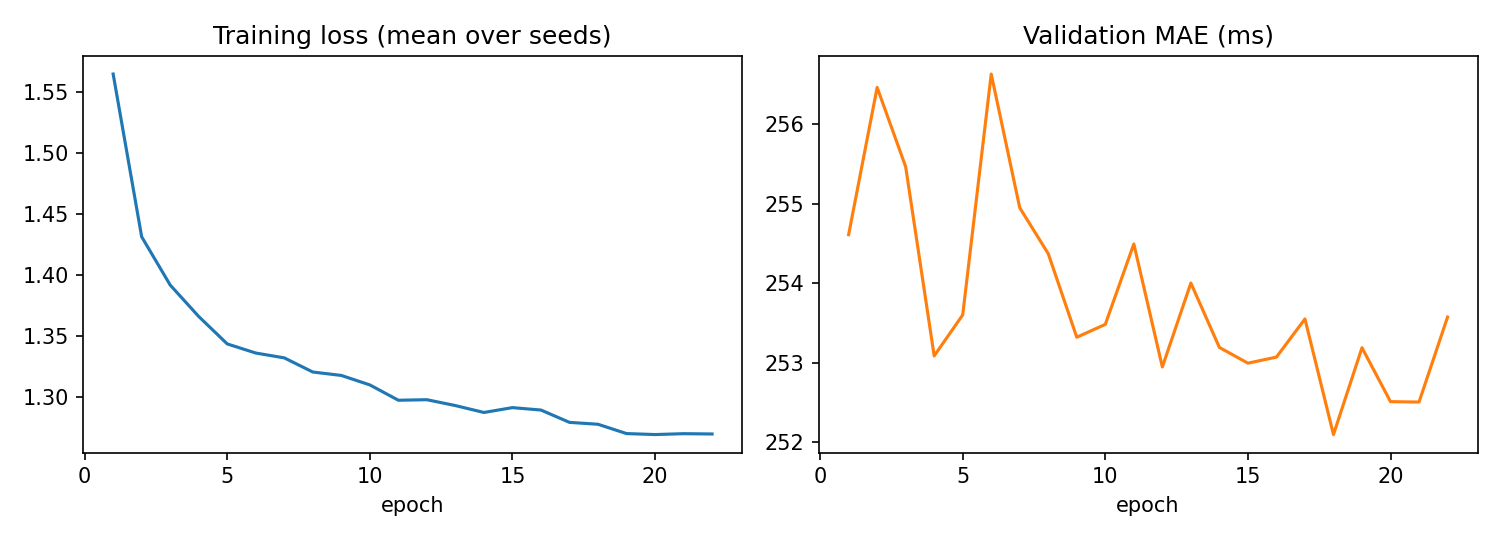

delay_prediction.png


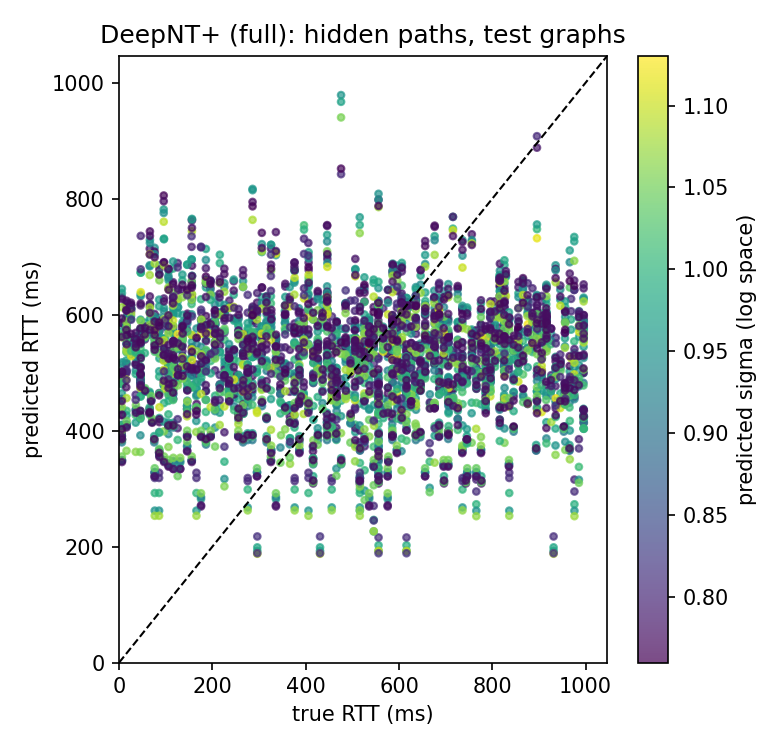

calibration.png


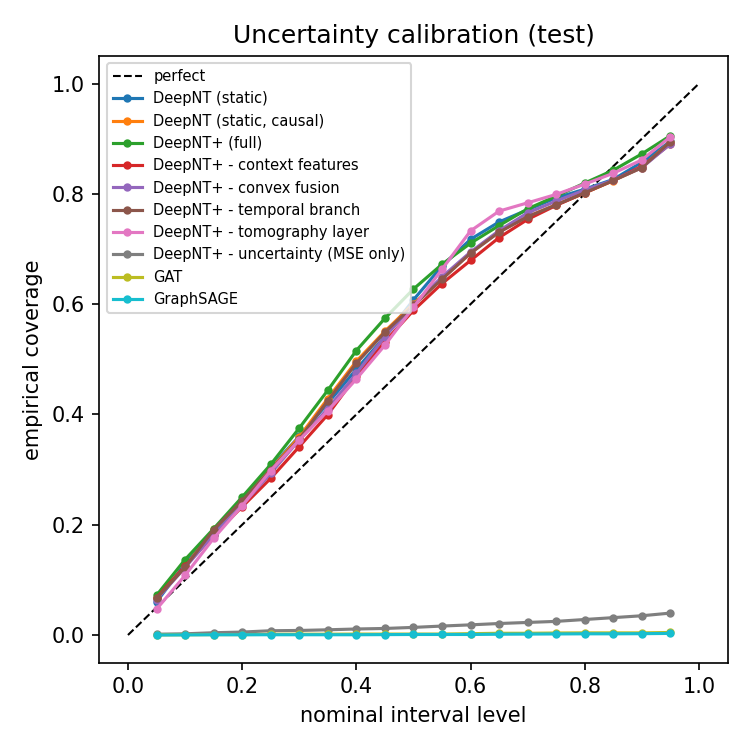

model_comparison.png


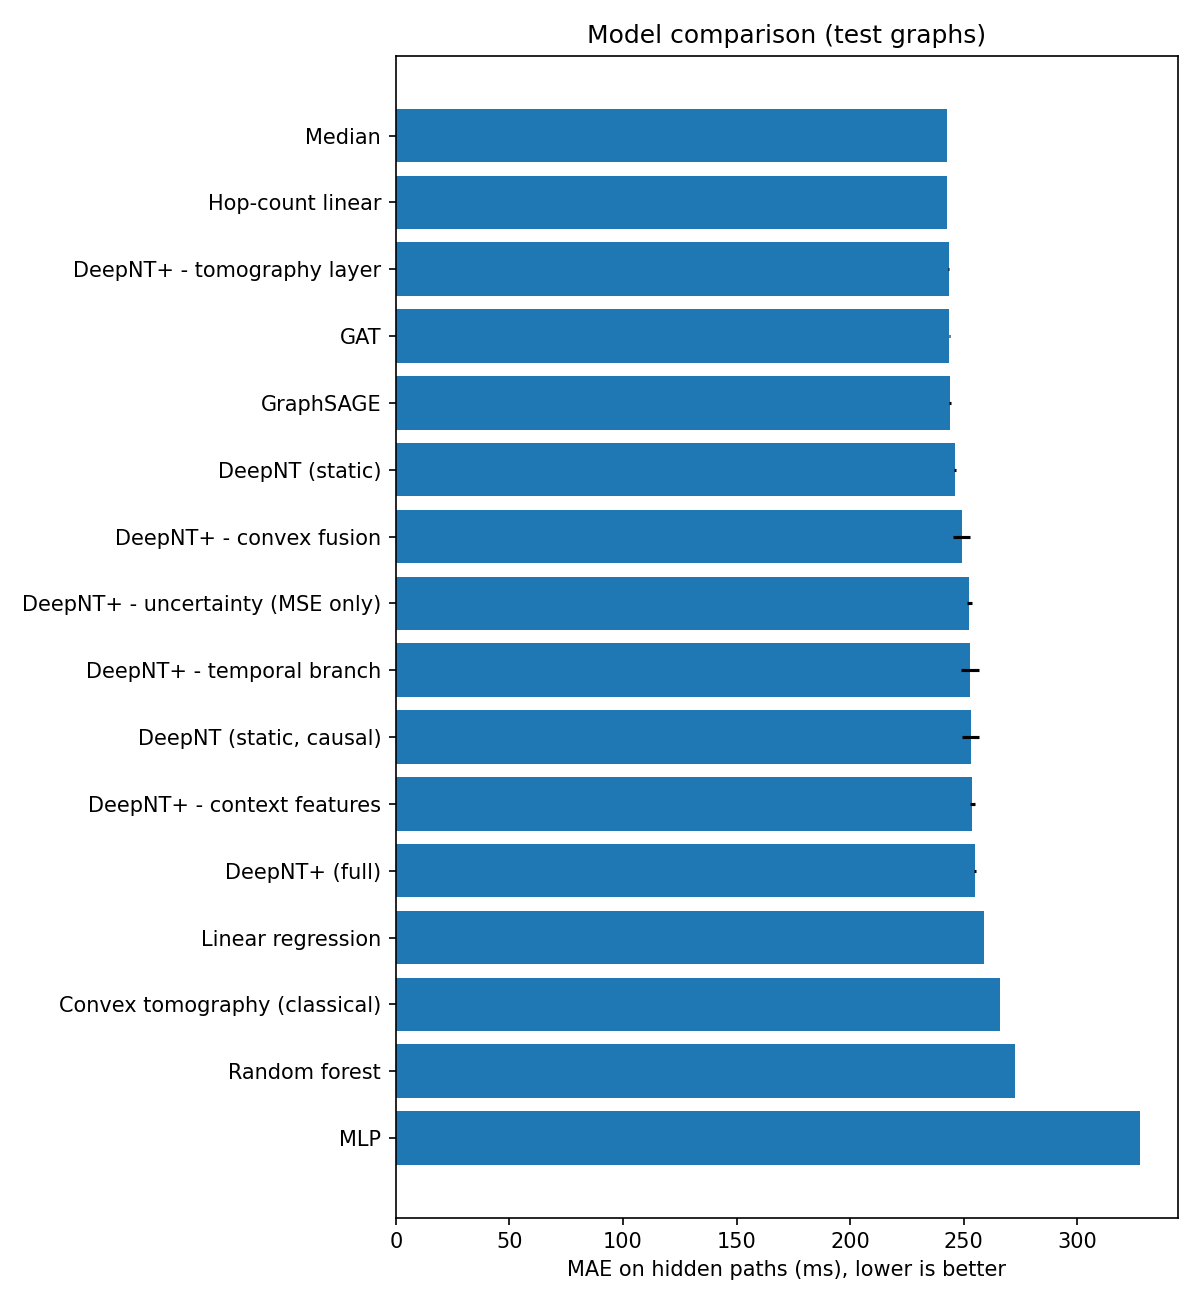

active_learning.png


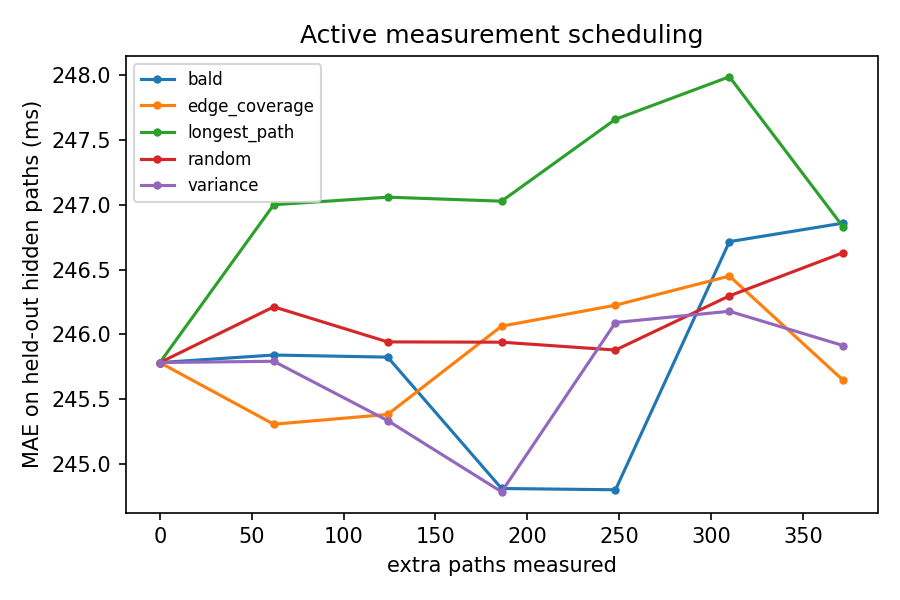

In [9]:
from IPython.display import Image, display
for f in report.make_all(OUT_DIR):
    print(f.name)
    display(Image(filename=str(f)))


## Cross-vantage-point test (optional)

Set `HOLDOUT_MONITOR` to one Ark monitor (for example `"dac-bd"`). Every graph dominated by that monitor becomes a test graph and the
model trains only on the other monitors. This is a much harder question than the standard split: does the model transfer to a vantage
point it has never seen? Expect worse numbers and read them as a robustness result.

In [10]:
HOLDOUT_MONITOR = None        # e.g. "dac-bd"
if HOLDOUT_MONITOR:
    hold_dir = OUT_DIR.parent / f"{RUN_NAME}_holdout_{HOLDOUT_MONITOR}"
    _, hold_summary = run_all(PROCESSED, hold_dir, seeds=SEEDS, epochs=EPOCHS, variants=["GraphSAGE", "DeepNT (static)"],
                              ablations=False, active_learning=False, fast=FAST, holdout_monitor=HOLDOUT_MONITOR)
    hc = [c for c in ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean"] if c in hold_summary.columns]
    print(f"test = graphs dominated by {HOLDOUT_MONITOR}; results saved to {hold_dir}")
    print(hold_summary[hold_summary.split == "test"][hc].sort_values("MAE_mean").round(3).to_string(index=False))
else:
    print("set HOLDOUT_MONITOR to run the cross-vantage-point test")


set HOLDOUT_MONITOR to run the cross-vantage-point test


## How to read these results

- **Claims you can make:** the model predicts the RTT of hidden paths on unseen graphs; how far it beats the baselines; how well its uncertainty is
  calibrated; which components matter (only where the ablation gap exceeds the seed spread); whether uncertainty-driven measurement scheduling beats random.
- **Claims you cannot make yet:** anything about packet loss (no labels), long-horizon temporal dynamics (the measurements cover about two days and
  almost no path repeats), or comparisons with RIPE Atlas or EvolveGCN (not in this dataset / not implemented).
- **Where the temporal branch can help:** only if RTT drifts within the two days. If `DeepNT+ (full)` does not beat `DeepNT (static, causal)` by more
  than the seed spread, report that honestly: it is a legitimate finding about this data, not a bug.
